# Comparación base y alternativa de VOC

Esta libreta lee dos ejecuciones guardadas del CLI. No ajusta modelos ni consulta un LLM.
La muestra se fijó antes del filtro, por plataforma y mes (julio–agosto de 2026), semilla 42.
Ambos sistemas usan UMAP 5D, HDBSCAN `eom` y KeyBERTInspired + MMR.
Base usa Robertuito original; alternativa aplica el SVM social y tiendas v3 a todas las fuentes.

Las distribuciones son predicciones, no métricas de exactitud. No conocemos los IDs del entrenamiento de sentimiento.
La transferencia de tiendas v3 a fuentes sociales no tiene aquí una referencia independiente.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/voc").is_dir())
NB_ROOT = REPO / "reports/difusion"
if str(NB_ROOT) not in sys.path: sys.path.insert(0, str(NB_ROOT))
from apoyo_validacion import digest, export_bundle, show_texts
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
import json
from pathlib import Path
from dataclasses import asdict
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from voc.analysis.store import read_analysis
from voc.datasets.manifest import file_hash
from voc_ml.experiments.operations import load_protocol
from voc.paths import data_root

ROOT = data_root() / "experiments/julaug-2026"
protocol = load_protocol(ROOT)
runs = {s: json.loads((ROOT / f"{s}-run.json").read_text()) for s in ("base", "alternative")}
assert all(r["state"] == "completed" for r in runs.values())
analyses = {s: read_analysis(r["representation"]["analysis_id"]) for s, r in runs.items()}
frames = {}
for s, saved in analyses.items():
    sentiment = pd.DataFrame([asdict(x) for x in saved.sentiments])
    assignments = pd.DataFrame([asdict(x) for x in saved.assignments])
    frames[s] = saved.reviews.merge(sentiment, on="record_id", validate="one_to_one").merge(assignments, on="record_id", validate="one_to_one")
    assert len(frames[s]) == saved.manifest.coverage["selected_reviews"]
    assert runs[s]["representation"]["tracking_verified"]
    assert frames[s].status.eq("classified").all()
verdict = pd.read_csv(ROOT / "relevance.csv")
assert set(frames["base"].record_id) == set(verdict.record_id)
assert set(frames["alternative"].record_id) == set(verdict.loc[verdict.keep, "record_id"])
paired = frames["base"][["record_id", "model_text", "model_label", "platform"]].merge(frames["alternative"][["record_id", "model_text", "model_label"]], on="record_id", suffixes=("_base", "_alternative"), validate="one_to_one")
assert paired.model_text_base.equals(paired.model_text_alternative)
print("Protocolo:", protocol["protocol_id"])
print("Intersección verificada:", len(paired))

Protocolo: 9c226c3c1b26b1382c5859024b85b3c5b0692319dcc9bf2f9b6a9c79d8672a53
Intersección verificada: 987


## Cobertura y retención

La asignación proporcional conserva las proporciones de la población elegible, con pocos casos de YouTube.
Las exclusiones son decisiones automáticas del SVM; no se consideran irrelevantes confirmados por una persona.

In [3]:
retention = verdict.groupby("platform").agg(initial=("keep", "size"), retained=("keep", "sum"))
retention["removed"] = retention.initial - retention.retained
display(retention)
rows = []
for s, saved in analyses.items():
    rows.append({"system": s, **saved.manifest.coverage, "wall_seconds": runs[s]["wall_seconds"]})
display(pd.DataFrame(rows))

,initial,retained,removed
platform,,,
app_store,49,49,0
google_play,876,876,0
x,64,62,2
youtube,11,0,11


,system,assigned_reviews,classified,excluded,failed,selected_reviews,topic_count,unassigned_reviews,wall_seconds
0,base,953,1000,0,0,1000,18,47,51.426846
1,alternative,846,987,0,0,987,28,141,45.183917


## Sentimiento sobre los mismos textos

La tabla cruza predicciones sobre la intersección. No es una matriz de confusión: ninguno de sus ejes es una etiqueta humana.
Los porcentajes de la figura comparten denominador. Un cambio de etiqueta no equivale a una corrección.

model_label_alternative,negative,neutral,positive
model_label_base,,,
negative,384,43,39
neutral,25,4,207
positive,0,0,285


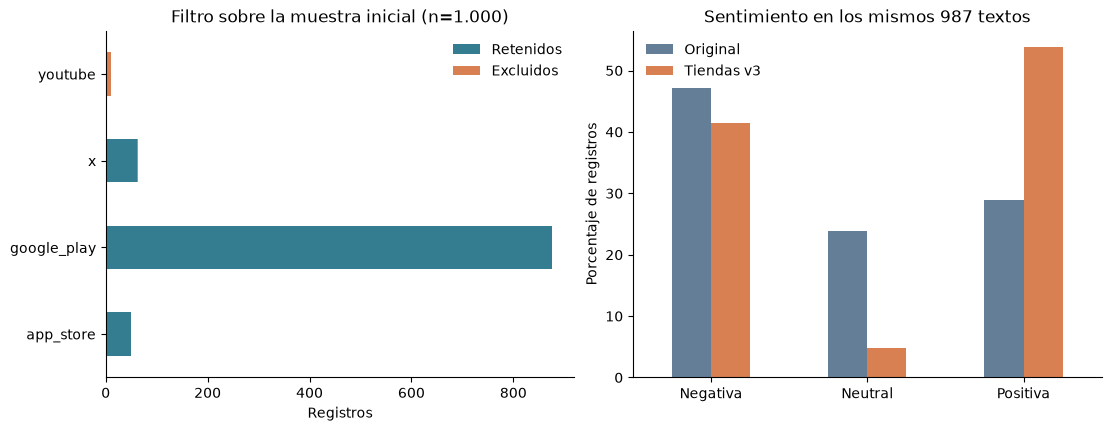

In [4]:
labels = ["negative", "neutral", "positive"]
transitions = pd.crosstab(paired.model_label_base, paired.model_label_alternative).reindex(index=labels, columns=labels, fill_value=0)
common_counts = pd.DataFrame({"Original": paired.model_label_base.value_counts(), "Tiendas v3": paired.model_label_alternative.value_counts()}).reindex(labels, fill_value=0)
assert int(transitions.to_numpy().sum()) == len(paired)
assert common_counts.sum().eq(len(paired)).all()
display(transitions)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
retention[["retained", "removed"]].rename(columns={"retained":"Retenidos", "removed":"Excluidos"}).plot.barh(stacked=True, ax=axes[0], color=["#347d91", "#d88052"])
axes[0].set(xlabel="Registros", ylabel="", title="Filtro sobre la muestra inicial (n=1.000)")
(common_counts / len(paired) * 100).rename(index={"negative":"Negativa", "neutral":"Neutral", "positive":"Positiva"}).plot.bar(ax=axes[1], color=["#657e98", "#d88052"], rot=0)
axes[1].set(ylabel="Porcentaje de registros", xlabel="", title=f"Sentimiento en los mismos {len(paired)} textos")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.show()

## Tópicos y ejemplos para revisar

Se ordenan todos los tópicos por tamaño (desempate por ID). Para revisar texto completo,
se muestran los tres mayores de cada sistema y su evidencia guardada, sin elegir ejemplos favorables.
Los IDs de tópico pertenecen a cada ajuste y no se emparejan por su número.
Esta inspección no asigna automáticamente una funcionalidad ni valida la calidad semántica.

In [5]:
topic_tables = {}
review_cases = {}
for s, saved in analyses.items():
    sizes = frames[s].topic_id.value_counts()
    table = pd.DataFrame([{"topic_id": t.topic_id, "size": int(sizes.get(t.topic_id, 0)), "keywords": ", ".join(k.term for k in t.keywords)} for t in saved.topics if t.topic_id >= 0]).sort_values(["size", "topic_id"], ascending=[False, True])
    topic_tables[s] = table
    print(s)
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
        display(table)
    review_cases[s] = []
    lookup = saved.reviews.set_index("record_id")
    for tid in table.head(3).topic_id:
        topic = next(t for t in saved.topics if t.topic_id == tid)
        evidence = [{"record_id": rid, "text": lookup.loc[rid, "model_text"]} for rid in topic.evidence_ids]
        review_cases[s].append({"topic_id": int(tid), "evidence": evidence})
        print("Tópico", tid)
        for item in evidence:
            print(item["record_id"] + "\n" + item["text"] + "\n")

base


,topic_id,size,keywords
0,0,529,"app, aplicación, no abre, tarjeta, banamex, abrir, no puedo, abre, no deja, puedo"
1,1,56,"excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfeccion, seria perfecto, perfecto no, existe tal, no existe"
2,2,38,"excelente aplicación, buena aplicación, aplicación muy, accesible, operatividad app, seguridad excelente, muy segura, recomendada, mucha seguridad, muy buena"
3,3,34,"todo bien, excelente bien, bien funciona, gracias mejorarla, mejorado todo, funciona muy, mejorar mucho, operacion vamos, mejoraron muchísimo, funciona cuando"
4,4,30,"excelente servicio, servicio excelente, servicio buen, buen servicio, servicio muy, muy buenos, muy profesional, profesional amabilidad, otorga empresa, operaciones teléfono"
5,5,30,"fácil usar, usar fácil, útil sencilla, muy fácil, fácil rápida, fácil muy, fácil rápido, práctica fácil, rápido fácil, necesita sencilla"
6,6,30,"app buena, buena app, app excelente, excelente app, encanta app, ya mejoró, mejoró, día mejorando, está buena, calidad"
7,7,28,"muy buena, muy bueno, buena muy, buena buena, buena excelente, buena gusta, buena apiclascion, excelente tarjeta, tarjeta tengo, cambiaría nada"
8,8,25,"excelente aplicación, excelente aplicacion, aplicación buena, buena aplicación, aplicación excelente, maravillosa aplicación, gran utilidad, funcionalidades muy, excelente organización, excelente todas"
9,9,23,"exelente exelenete, exelente exelente, mala execelente, versatil didáctica, satisfecho magnigico, pesima versatil, datos confusos, mercado exelente, rateros rateros, peor mercado"


Tópico 0
play:com.citibanamex.banamexmobile:71c77ad8-78a7-4a2b-a819-abae8a3cef0c
muy mala aplicación últimamente no me deja acceder desde ase como 20 días a estado fallando mucho pues entro ala aplicación y solo se pone obscura la pantalla antes era muy buena solucionen ese problema pues para poder entrar tengo que estar reiniciando el teléfono acá rato y si bien logro acceder ala aplicación si no seguir intentando una y otra ves y es muy molesto

play:com.citibanamex.banamexmobile:73962522-0930-4d71-8799-3932bf49a89e
pésima experiencia con Banamex no solo su app, el cajero más cercano a mi casa nunca tiene dinero, o tiene errores, la app igual abre cuando quiere, no muestran los movimientos que uno hace sino hasta varios días después, lo único bueno son sus tarjetas de crédito muchas promociones en todos lados, pero está atrasados como banco, recién implementaron lo de retiro sin tarjeta y lo de poder cargar tiempo aire cuando otros bancos ya tenían esos servicios mucho antes

youtube

,topic_id,size,keywords
0,0,105,"app queda, abrir app, app, abre, pantalla, pantalla azul, actualización, congelada, azul, 2026"
1,1,73,"tarda mucho, no deja, tener esperar, abre tarda, 15 días, cualquier hora, mucho abrir, nunca abre, algunas veces, movimientos no"
2,2,66,"app banco, app tarda, aplicación banco, banca móvil, bancaria, banca, otros bancos, entrar banca, acceso, hacer transferencias"
3,3,61,"móvil banamex, banamex app, app banamex, aplicación banamex, banamex no, app no, banamexcontacto, app ya, no funciona, audiomatico"
4,4,54,"excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfecto, perfeccion, seria perfecto, perfecto no, no existe"
5,5,35,"muy eficiente, muy eficas, mejoraron rapidez, eficiente buena, rápida muy, eficiente, muy útil, eficiente práctica, información rápida, funcional práctica"
6,6,34,"servicio buen, buen servicio, excelente servicio, servicio excelente, servicio muy, muy recomendable, clientes, otorga empresa, nuestras necesidades, necesidades ojo"
7,7,32,"todo bien, bien funciona, excelente bien, funciona muy, gracias mejorarla, mejorado todo, mejorar mucho, satisfecho debe, funciona cuando, operacion vamos"
8,8,32,"mejoró app, app buena, buena app, app excelente, mejoraron aplicación, mejoró, mejorando excelente, mejor calidad, mejorado muchisimo, mejorado"
9,9,29,"muy buena, muy bueno, buena muy, buena buena, buena excelente, buena apiclascion, excelente tarjeta, buena practica, tarjeta tengo, cambiaría nada"


Tópico 0
play:com.citibanamex.banamexmobile:a4843162-7c2c-449a-95a3-29f1f261d3ff
todo absolutamente todo esta mal. quienes diseñaron todo desde la app , el centro de ayuda y todo , deberían ser despedidos , como que necesitas un código para tener ayuda por telefono ? y luego su intento de ia ni te intenta ayudar , y se equivoca! , los operadores ni te pueden ayudar con la app. La app no funciona de plano , se buguea demasiado , no valen el 1 de cashback si la aplicación es asi de mala , voy a cancelar la cuenta de una vez, ni una semana me duró el gusto.

play:com.citibanamex.banamexmobile:71c77ad8-78a7-4a2b-a819-abae8a3cef0c
muy mala aplicación últimamente no me deja acceder desde ase como 20 días a estado fallando mucho pues entro ala aplicación y solo se pone obscura la pantalla antes era muy buena solucionen ese problema pues para poder entrar tengo que estar reiniciando el teléfono acá rato y si bien logro acceder ala aplicación si no seguir intentando una y otra ves y es muy mole

## Revisión de todas las exclusiones

Se muestran las 13 decisiones de exclusión, sin seleccionar casos favorables.
La inspección inicial de Codex señaló menciones a NetKey móvil, transferencias y CVV dinámico.
La revisión humana posterior se registra en la siguiente sección: no confirmó todas las sospechas del asistente.

In [6]:
excluded = verdict.loc[~verdict.keep].merge(frames["base"][["record_id", "model_text"]], on="record_id", validate="one_to_one")
for row in excluded.itertuples():
    print(row.record_id, row.platform, "\n" + row.model_text + "\n")

x:2081120493025788406 x 
Si intentaste entrar a tu aplicación de Banamex o BBVA y tuviste problemas al momento de ingresar, realizar un pago o completar transferencia no eres el único:

https://t.co/wIssZel8iZ

x:2089042705733034080 x 
Se acuerdan cuando era sencillo comprar un pinche boleto de cine? Entrabas ponías tu tarjeta su cvv y listo. Ahora son pinches códigos de verificación @cinepolis al correo y abrir la pinche app d @banamex para un puto cvv dinámico y la app de wallet para agregar el puto boleto 🖕

youtube:-:UgwAtme4E0RfWGHsfKR4AaABAg youtube 
muchas gracias, muy util la informacion

youtube:-:UgwDg5VRdDTS-o1iyEd4AaABAg youtube 
Llamé y fui a sucursal y me confirmaron que es un error de sistema, me comentaron que tecnologías está trabajando para solucionarlo para colocarlo manual.

youtube:-:UgxYG8tABED-v4SkGC14AaABAg youtube 
Sigue sin funcionar

youtube:-:UgyG4ynvY5oTDZZ4Sj94AaABAg youtube 
No puedo sacar en efectivo

youtube:-:UgydifHTT3edi4Lvvy94AaABAg youtube 
Me lleg

## Registro de revision manual

El usuario revisó los 13 casos y marcó **10 irrelevantes y 3 relevantes**: uno de X y dos de YouTube fueron excluidos incorrectamente según esa revisión. El caso de CVV dinámico fue considerado irrelevante; se conserva esa decisión, distinta de la sospecha inicial del asistente.

Se revisaron todos los excluidos, pero no todos los retenidos. Por eso estos recuentos no proporcionan recall ni exactitud global del filtro. La revisión fue posterior a ver las decisiones y observaciones asistidas; no fue ciega.

El usuario percibió mayor relación con la app en los ejemplos de la alternativa. La reseña citada pertenece al tópico 0 en ambos ajustes y aparece como evidencia representativa solo en la alternativa. Esto describe lo mostrado, no demuestra que el base careciera de ese contenido. No se validaron etiquetas individuales de sentimiento.

El modelo y los resultados originales se conservan; esta revisión no vuelve a entrenar ni modifica las asignaciones.

In [7]:
human_review = json.loads((ROOT / "human-review-v1/review.json").read_text())
assert human_review["protocol_id"] == protocol["protocol_id"]
review_df = pd.DataFrame(human_review["rows"])
assert set(review_df.record_id) == set(excluded.record_id)
assert len(review_df) == 13
assert review_df.human_label.value_counts().to_dict() == {"irrelevant": 10, "relevant": 3}
display(pd.crosstab(review_df.platform, review_df.human_label))
with pd.option_context("display.max_colwidth", None):
    display(review_df.loc[review_df.human_label.eq("relevant"), ["record_id", "platform", "human_label"]])
print("Fuente de la revisión:", human_review["source"])

human_label,irrelevant,relevant
platform,,
x,1,1
youtube,9,2


,record_id,platform,human_label
0,x:2081120493025788406,x,relevant
8,youtube:-:UgygzHzdimxwtndEhEt4AaABAg,youtube,relevant
10,youtube:-:UgzKXYFlIc0bBikF2V54AaABAg,youtube,relevant


Fuente de la revisión: journal/linear/WOR-228-producto-difusion/context/buffer.md


## Estructura de tópicos: concentración y cobertura

**Pregunta:** ¿cómo cambia la distribución de los grupos? Ordenamos por tamaño, no por equivalencia temática: el rango 1 del base no identifica el mismo tópico que el rango 1 de la alternativa. `-1` se contabiliza fuera de los tópicos. Los porcentajes usan los 1.000 y 987 registros de cada sistema; el porcentaje del grupo mayor se calcula sobre todas las filas procesadas.

Las barras describen resultados. Una partición más fina o menos concentrada no demuestra mayor utilidad, y una reseña sin grupo puede contener información valiosa.


,system,rows,topics,unassigned,unassigned_pct,largest,largest_pct,median_topic_size
0,base,1000,18,47,4.70,529,52.90,24.0
1,alternative,987,28,141,14.29,105,10.64,23.0


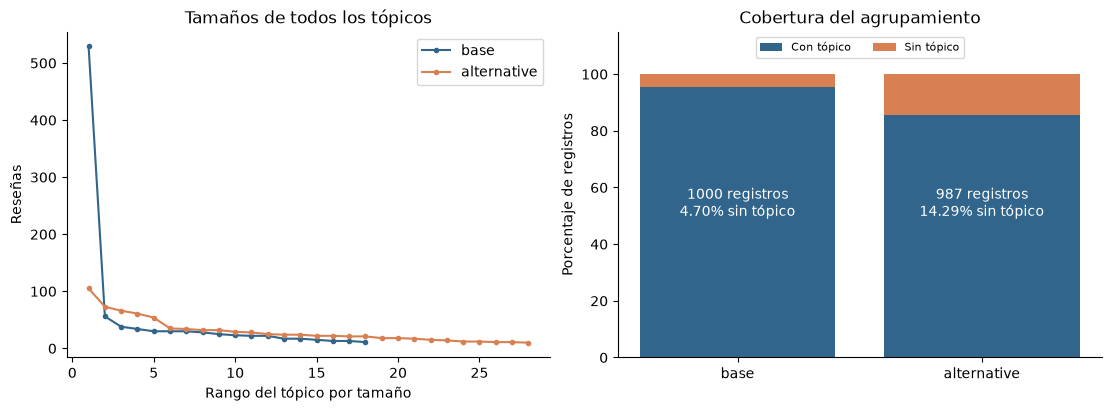

In [8]:
structure_rows = []
for system, table in topic_tables.items():
    total = len(frames[system]); missing = int(frames[system].topic_id.eq(-1).sum())
    assert int(table["size"].sum()) + missing == total
    structure_rows.append({"system": system, "rows": total, "topics": len(table),
                          "unassigned": missing, "unassigned_pct": 100*missing/total,
                          "largest": int(table["size"].max()), "largest_pct": 100*table["size"].max()/total,
                          "median_topic_size": float(table["size"].median())})
structure = pd.DataFrame(structure_rows)
display(structure.round(2))
fig_structure, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for system, color in [("base", "#31658B"), ("alternative", "#D88052")]:
    sizes = topic_tables[system].sort_values(["size", "topic_id"], ascending=[False, True])["size"].to_numpy()
    ax[0].plot(np.arange(1, len(sizes)+1), sizes, marker="o", markersize=3, label=system, color=color)
ax[0].set(xlabel="Rango del tópico por tamaño", ylabel="Reseñas", title="Tamaños de todos los tópicos")
ax[0].legend()
ax[1].bar(structure.system, 100-structure.unassigned_pct, label="Con tópico", color="#31658B")
ax[1].bar(structure.system, structure.unassigned_pct, bottom=100-structure.unassigned_pct, label="Sin tópico", color="#D88052")
for i, row in structure.iterrows(): ax[1].text(i, 50, f"{row.rows} registros\n{row.unassigned_pct:.2f}% sin tópico", ha="center", color="white")
ax[1].set(ylabel="Porcentaje de registros", ylim=(0, 115), title="Cobertura del agrupamiento")
ax[1].legend(loc="upper center", ncol=2, fontsize=8)
plt.show()


## Palabras clave: diversidad y asociación léxica

Usamos las primeras diez palabras o bigramas guardados por tópico después de KeyBERTInspired + MMR. La **diversidad** es términos distintos / posiciones de términos, sin descomponer los bigramas. Cambia con el número de tópicos; no es un ranking de calidad.

Como diagnóstico adicional calculamos **NPMI por documento**: cada reseña cuenta una vez para la presencia de un término, con el analizador de unigramas/bigramas y stopwords del proyecto. Para términos presentes en el corpus de referencia:

$$\mathrm{NPMI}(a,b)=\frac{\log[p(a,b)/(p(a)p(b))]}{-\log p(a,b)}.$$

El corpus de referencia es el mismo para ambos sistemas: las 1.000 reseñas iniciales, incluidos textos repetidos. Si dos términos presentes nunca coocurren asignamos −1; si un término no aparece o ambos aparecen en todos los documentos, el par queda indefinido y se registra aparte. La tabla informa cobertura de términos y pares. Se promedia primero por tópico y después entre tópicos con pares evaluables, sin ponderar por tamaño.

Esta variante por documento **no reproduce** la evaluación del artículo ni `c_v` con ventanas deslizantes. Un bigrama y una palabra contenida en él pueden aumentar la asociación por construcción. Los términos ausentes pueden surgir al agregar documentos para c-TF-IDF. No evaluamos coherencia semántica humana ni estabilidad entre semillas. Referencia conceptual: [BERTopic, evaluación](https://arxiv.org/html/2203.05794v1), [Gensim, medidas de coherencia](https://radimrehurek.com/gensim/topic_coherence/direct_confirmation_measure.html).

La celda también comprueba si un término ausente en las reseñas del tópico aparece al concatenarlas. Esto permite detectar bigramas formados en fronteras entre documentos. No se modifica el pipeline ni se corrigen retrospectivamente sus términos. La media excluye pares indefinidos: debe leerse junto con su cobertura, sin declarar un ganador por NPMI.


In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from voc_ml.topics.bertopic import STOP_WORDS
from apoyo_validacion import lexical_metrics
analyzer = CountVectorizer(stop_words=list(STOP_WORDS), ngram_range=(1,2)).build_analyzer()
lexical_tables = {}; lexical_rows = []
for system, saved in analyses.items():
    topics_ordered = sorted((t for t in saved.topics if t.topic_id >= 0), key=lambda t:t.topic_id)
    terms = [[k.term for k in t.keywords][:10] for t in topics_ordered]
    metrics, diversity = lexical_metrics(terms, frames["base"].model_text.tolist(), analyzer)
    metrics.insert(0,"topic_id",[t.topic_id for t in topics_ordered]);metrics.insert(0,"system",system)
    lexical_tables[system] = metrics
    lexical_rows.append({"system":system, **diversity, "mean_document_npmi":metrics.npmi_document.mean(),
                         "evaluable_topics":int(metrics.npmi_document.notna().sum()),
                         "term_coverage":metrics.terms_found.sum()/metrics.terms.sum(),
                         "pair_coverage":metrics.evaluated_pairs.sum()/metrics.pairs.sum()})
lexical_summary = pd.DataFrame(lexical_rows)
display(lexical_summary.round(4))
display(pd.concat(lexical_tables.values(), ignore_index=True))

# Diagnóstico de bigramas ausentes: distinguir vocabulario por documento y agregado.
term_rows=[]
reference_terms=set(term for text in frames["base"].model_text for term in analyzer(text))
for system,saved in analyses.items():
    for topic in saved.topics:
        if topic.topic_id < 0:continue
        members=frames[system].loc[frames[system].topic_id.eq(topic.topic_id),"model_text"]
        member_terms=set(term for text in members for term in analyzer(text))
        aggregate_terms=set(analyzer(" ".join(members)))
        for keyword in topic.keywords[:10]:
            term_rows.append({"system":system,"topic_id":topic.topic_id,"term":keyword.term,
                "in_reference_review":keyword.term in reference_terms,
                "in_member_review":keyword.term in member_terms,
                "in_concatenated_members":keyword.term in aggregate_terms,
                "only_after_concatenation":keyword.term in aggregate_terms and keyword.term not in member_terms})
term_presence=pd.DataFrame(term_rows)
display(term_presence.groupby("system").agg(term_slots=("term","size"),
    present_in_reference=("in_reference_review","sum"),
    present_only_after_concatenation=("only_after_concatenation","sum")))
print("La cobertura de pares difiere: no usar estas medias NPMI como ranking ni como validación semántica.")


,system,unique_terms,term_slots,diversity,reference_rows,mean_document_npmi,evaluable_topics,term_coverage,pair_coverage
0,base,174,180,0.9667,1000,-0.6346,17,0.7056,0.5346
1,alternative,275,280,0.9821,1000,-0.7287,28,0.7750,0.6310


,system,topic_id,npmi_document,terms,terms_found,pairs,evaluated_pairs,oov_pairs,degenerate_pairs,zero_cooccurrence_pairs
0,base,0,0.093521,10,10,45,45,0,0,1
1,base,1,0.428571,10,7,45,21,24,0,6
2,base,2,-0.614217,10,9,45,36,9,0,26
3,base,3,-0.928571,10,8,45,28,17,0,27
4,base,4,-0.928571,10,8,45,28,17,0,27
5,base,5,-0.822212,10,9,45,36,9,0,32
6,base,6,-0.763077,10,8,45,28,17,0,24
7,base,7,-0.773066,10,7,45,21,24,0,18
8,base,8,-0.815602,10,8,45,28,17,0,25
9,base,9,-1.000000,10,3,45,3,42,0,3


,term_slots,present_in_reference,present_only_after_concatenation
system,,,
alternative,280,217,68
base,180,127,55


La cobertura de pares difiere: no usar estas medias NPMI como ranking ni como validación semántica.


## Revisión temática preparada: doce casos fijos

**Selección:** ordenar los tópicos de cada sistema por tamaño e ID, dividir sus rangos en tres bandas aproximadamente iguales y escoger dos por banda mediante SHA-256 con semilla declarada 42. Las bandas son relativas a cada sistema; no se equiparan sus tamaños absolutos. Para cada grupo mostramos cinco textos distintos por orden hash y hasta dos ejemplos guardados adicionales, evitando repetir texto. Estos últimos son ejemplos seleccionados por el modelo, no una muestra aleatoria. Con pocos textos no se valida todo el grupo.

La selección queda fijada antes de recibir juicios, pero es una revisión posterior al experimento. Los sistemas se identifican y algunos grupos pudieron verse antes: **no es ciega ni una prueba reservada**. Doce grupos no equivalen a doce funcionalidades confirmadas.

### Criterios para completar el CSV

En `revision-manual/topicos.csv`, completa estas columnas después de leer las tarjetas:

- `coherencia`: 0 = asuntos sin relación clara; 1 = núcleo común con mezcla; 2 = asunto común claro en los textos mostrados; `no_evaluable` = evidencia insuficiente.
- `palabras_clave`: 0 = no describen el asunto; 1 = descripción parcial o genérica; 2 = descripción clara; `no_evaluable`.
- `tipo_asunto`: `funcionalidad`, `mixto`, `valoracion_general`, `otro` o `no_evaluable`.
- `justificacion`, `revisor` y `fecha`: explicación breve, identificador del revisor y fecha.

No cambies las columnas de identidad. Las celdas siguientes crean el CSV solo si no existe; nunca sobrescriben respuestas. Guarda el archivo y vuelve a ejecutar desde la celda que lo lee hasta la exportación. No uses estas apreciaciones como etiquetas de sentimiento. Se conserva aparte la revisión manual de exclusiones ya realizada.


In [10]:
from apoyo_validacion import topic_review_cases, review_sheet
review_cases_topics, review_selection = topic_review_cases(topic_tables, frames, analyses)
assert len(review_selection) == 12 and review_selection.case_id.is_unique
review_path = NB_ROOT / "revision-manual/topicos.csv"
review = review_sheet(review_path, review_selection, protocol["protocol_id"])
display(review_selection)
for case in review_cases_topics:
    print(f"{case['case_id']} · banda {case['band']} · {case['size']} reseñas")
    print(case["keywords"])
    show_texts(case["reviews"])


,case_id,system,topic_id,band,size,keywords
0,base:13,base,13,pequeno,17,"rápida efectiva, rápida eficaz, muy eficiente,..."
1,base:16,base,16,pequeno,13,"útil buena, muy práctica, eficas buena, confia..."
2,base:7,base,7,mediano,28,"muy buena, muy bueno, buena muy, buena buena, ..."
3,base:9,base,9,mediano,23,"exelente exelenete, exelente exelente, mala ex..."
4,base:1,base,1,grande,56,"excelentes excelente, perfeccion excelente, ex..."
5,base:2,base,2,grande,38,"excelente aplicación, buena aplicación, aplica..."
6,alternative:26,alternative,26,pequeno,11,"felicidades banamex, banamex excelente, excele..."
7,alternative:19,alternative,19,pequeno,18,"buena, buena cool, buena buena, buena ap, ap b..."
8,alternative:13,alternative,13,mediano,24,"muchas fallas, tiene fallas, fallas demás, hay..."
9,alternative:16,alternative,16,mediano,21,"excelente atención, eficiente gracias, content..."


base:13 · banda pequeno · 17 reseñas
rápida efectiva, rápida eficaz, muy eficiente, rápida axesible, mejoraron rapidez, práctica rápida, práctico eficiente, eficiente, eficiente práctica, información rápida


base:16 · banda pequeno · 13 reseñas
útil buena, muy práctica, eficas buena, confiable clara, práctica confiable, cómoda práctica, segura practico, siempre confiable, buena relación, usarla funcional


base:7 · banda mediano · 28 reseñas
muy buena, muy bueno, buena muy, buena buena, buena excelente, buena gusta, buena apiclascion, excelente tarjeta, tarjeta tengo, cambiaría nada


base:9 · banda mediano · 23 reseñas
exelente exelenete, exelente exelente, mala execelente, versatil didáctica, satisfecho magnigico, pesima versatil, datos confusos, mercado exelente, rateros rateros, peor mercado


base:1 · banda grande · 56 reseñas
excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfeccion, seria perfecto, perfecto no, existe tal, no existe


... (3 outputs left out)

alternative:13 · banda mediano · 24 reseñas
muchas fallas, tiene fallas, fallas demás, hay fallas, fallas capacidad, fallas siempre, fallas problemas, fallando pésima, servicio pésimo, mucho aplicación


alternative:16 · banda mediano · 21 reseñas
excelente atención, eficiente gracias, contenta atención, genial gracias, exelente gracias, gracias exelente, gracias muy, excelente asesoró, rapido amables, cliente todo


alternative:2 · banda grande · 66 reseñas
app banco, app tarda, aplicación banco, banca móvil, bancaria, banca, otros bancos, entrar banca, acceso, hacer transferencias


alternative:8 · banda grande · 32 reseñas
mejoró app, app buena, buena app, app excelente, mejoraron aplicación, mejoró, mejorando excelente, mejor calidad, mejorado muchisimo, mejorado


In [11]:
# Recargar después de guardar el CSV de revisión; no llena juicios automáticamente.
review = review_sheet(review_path, review_selection, protocol["protocol_id"])
review_progress = review.groupby("system").agg(cases=("case_id", "size"), completed=("completa", "sum")).reset_index()
display(review_progress)
if not review.completa.any():
    print("Revisión temática pendiente: todavía no hay casos completos; no se calculan puntuaciones humanas.")
else:
    display(review.loc[review.completa, ["case_id", "coherencia", "palabras_clave", "tipo_asunto", "justificacion", "revisor", "fecha"]])
    print("Juicios sobre los casos revisados; no estiman precisión global ni superioridad del sistema.")


,system,cases,completed
0,alternative,6,0
1,base,6,0


Revisión temática pendiente: todavía no hay casos completos; no se calculan puntuaciones humanas.


## Desacuerdos de sentimiento: cambios, no correcciones

Los dos ejes de esta matriz son **predicciones**, no etiquetas humanas. Todas las celdas suman los mismos 987 registros. Seleccionamos hasta dos textos distintos por cada transición fuera de la diagonal mediante un orden hash fijo. Así incluimos las seis direcciones posibles, sin elegir solo ejemplos favorables. Las frecuencias son de todos los registros; las tarjetas son ejemplos, no una muestra para estimar exactitud.

Las estrellas, cuando existen, no se muestran como una verdad del sentimiento textual. Para una evaluación nueva harían falta referencias humanas y aclarar el solapamiento con el entrenamiento.


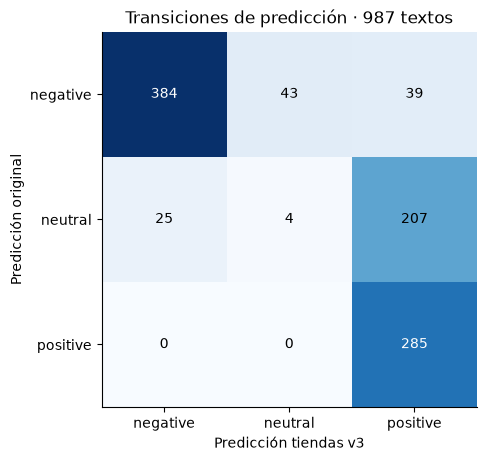

negative → neutral: 43 registros; 2 ejemplos


negative → positive: 39 registros; 2 ejemplos


neutral → negative: 25 registros; 2 ejemplos


neutral → positive: 207 registros; 2 ejemplos


positive → negative: 0 registros; 0 ejemplos
positive → neutral: 0 registros; 0 ejemplos


In [12]:
fig_transitions, ax = plt.subplots(figsize=(6,4.5), layout="constrained")
ax.imshow(transitions.to_numpy(), cmap="Blues")
for i in range(3):
    for j in range(3): ax.text(j,i,str(transitions.iloc[i,j]),ha="center",va="center",color="white" if transitions.iloc[i,j]>250 else "black")
ax.set(xticks=range(3),yticks=range(3),xticklabels=labels,yticklabels=labels,
       xlabel="Predicción tiendas v3",ylabel="Predicción original",title="Transiciones de predicción · 987 textos")
plt.show()
from apoyo_validacion import ranked_sample
sentiment_examples=[]
for before in labels:
    for after in labels:
        if before == after:continue
        subset=paired.loc[paired.model_label_base.eq(before)&paired.model_label_alternative.eq(after)].rename(columns={"model_text_base":"model_text"})
        selected=ranked_sample(subset,2,f"sentiment-v1:42:{before}:{after}")
        print(f"{before} → {after}: {len(subset)} registros; {len(selected)} ejemplos")
        columns=["record_id","platform","model_label_base","model_label_alternative","model_text"]
        show_texts(selected[columns])
        sentiment_examples.extend(selected[columns].to_dict("records"))
assert int((paired.model_label_base != paired.model_label_alternative).sum()) == 314


## Exportación

Exportamos los resultados de la libreta para elaborar el reporte.


In [13]:
source_paths = {"protocol": ROOT/"protocol.json", "base_run": ROOT/"base-run.json", "alternative_run": ROOT/"alternative-run.json", "relevance_decisions": ROOT/"relevance.csv", "human_exclusions":ROOT/"human-review-v1/review.json", "topic_review":review_path}
sources = {name:{"path":str(p.relative_to(REPO)), "sha256":digest(p)} for name,p in source_paths.items()}
for system,r in runs.items():
    p=data_root()/"analyses"/r["representation"]["analysis_id"]/"manifest.json"
    sources[system+"_analysis"]={"path":str(p.relative_to(REPO)),"sha256":digest(p)}
exported = export_bundle(NB_ROOT/"comparacion-base-alternativa.ipynb",
    {"topicos-estructura":fig_structure,"sentimiento-transiciones":fig_transitions,"comparacion-integrada":fig},
    {"topicos-resumen":structure,"topicos-lexico":pd.concat(lexical_tables.values(),ignore_index=True),
     "lexico-resumen":lexical_summary,"presencia-terminos":term_presence,"retencion":retention.reset_index(),
     "sentimiento-conteos-comunes":common_counts.rename_axis("label").reset_index(),
     "sentimiento-transiciones":transitions.rename_axis("original").reset_index(),
     "revision-topicos":review,"revision-progreso":review_progress,
     "topicos-base":topic_tables["base"],"topicos-alternativa":topic_tables["alternative"],
     "exclusiones-revisadas":review_df},
    {"casos-topicos":review_cases_topics,"ejemplos-sentimiento":sentiment_examples,
     "alcance":{"protocol_id":protocol["protocol_id"],"initial_rows":1000,"common_rows":len(paired),
                "changed_sentiment_labels":314,"human_topic_cases_completed":int(review.completa.sum()),
                "independent_sentiment_test":False,"npmi_policy":"document-presence-common-initial-sample-v1"}},
    sources, "Descriptive integrated comparison; lexical diagnostics; human topic review only when completed; no model reruns")


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/comparacion-base-alternativa/20261105T191417975479Z
